# Marked PPP Analysis – Radar Point Clouds

This notebook analyzes predictions of a **marked Poisson Point Process (PPP)** model
applied to **radar point cloud data**.

In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["image.cmap"] = "hot"

In [ ]:
# Root directory where PPPMarkVisualizationHook stored outputs
ROOT_DIR = "../ppp_vis"

assert os.path.isdir(ROOT_DIR), f"Directory not found: {ROOT_DIR}"

# Collect all samples by prefix
files = sorted(os.listdir(ROOT_DIR))
prefixes = sorted(
    set("_".join(f.split("_")[:3]) for f in files if f.endswith("_meta.json"))
)

print(f"Found {len(prefixes)} saved samples.")

Found 200 saved samples.


In [24]:
def load_sample(prefix, root=ROOT_DIR):
    sample = {}

    sample["img"] = np.load(os.path.join(root, f"{prefix}_img.npy"))
    sample["lambda_pred"] = np.load(os.path.join(root, f"{prefix}_lambda_pred.npy"))
    sample["lambda_gt"] = np.load(os.path.join(root, f"{prefix}_lambda_gt.npy"))

    meta_path = os.path.join(root, f"{prefix}_meta.json")
    with open(meta_path, "r") as f:
        sample["meta"] = json.load(f)

    # Optional marks
    depth_pred = os.path.join(root, f"{prefix}_depth_pred.npy")
    vel_pred   = os.path.join(root, f"{prefix}_velocity_pred.npy")

    sample["depth_pred"] = np.load(depth_pred) if os.path.exists(depth_pred) else None
    sample["vel_pred"]   = np.load(vel_pred) if os.path.exists(vel_pred) else None

    return sample

def list_samples(root=ROOT_DIR):
    files = sorted(os.listdir(root))
    prefixes = sorted(
        set("_".join(f.split("_")[:3]) for f in files if f.endswith("_meta.json"))
    )
    return prefixes


In [ ]:
from ipywidgets import Dropdown

prefixes = list_samples()

dropdown = Dropdown(options=prefixes, description="Sample:")
dropdown

ModuleNotFoundError: No module named 'ipywidgets'

In [25]:
idx = 140
# prefix = prefixes[idx]
prefixes = list_samples()
len(prefixes)

sample = load_sample(prefix)

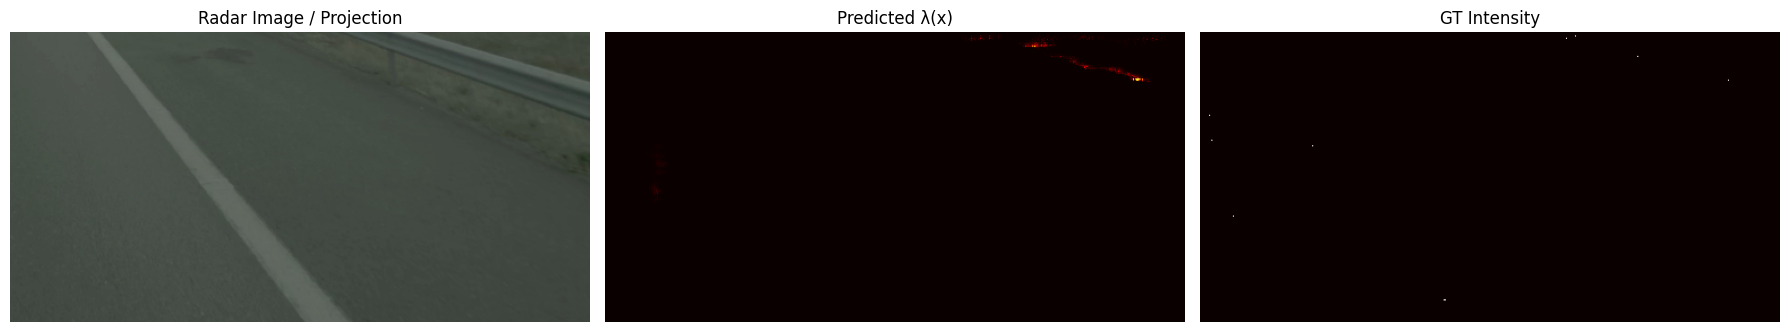

In [18]:
img = sample["img"]
lam = sample["lambda_pred"]
lam_gt = sample["lambda_gt"]

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

axs[0].imshow(img)
axs[0].set_title("Radar Image / Projection")

axs[1].imshow(lam)
axs[1].set_title("Predicted λ(x)")

axs[2].imshow(lam_gt)
axs[2].set_title("GT Intensity")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [19]:
H, W = lam.shape
pixel_area = H * W

lam_norm = lam / pixel_area
lam_gt_norm = lam_gt / pixel_area

expected_count = lam_norm.sum()
gt_count = lam_gt_norm.sum()

print("PPP Expected Count Diagnostic")
print("-----------------------------")
print(f"Expected count (∫λ dx): {expected_count:.3f}")
print(f"GT count:               {gt_count:.0f}")
print(f"Difference:             {expected_count - gt_count:+.3f}")


PPP Expected Count Diagnostic
-----------------------------
Expected count (∫λ dx): 3.532
GT count:               0
Difference:             +3.532


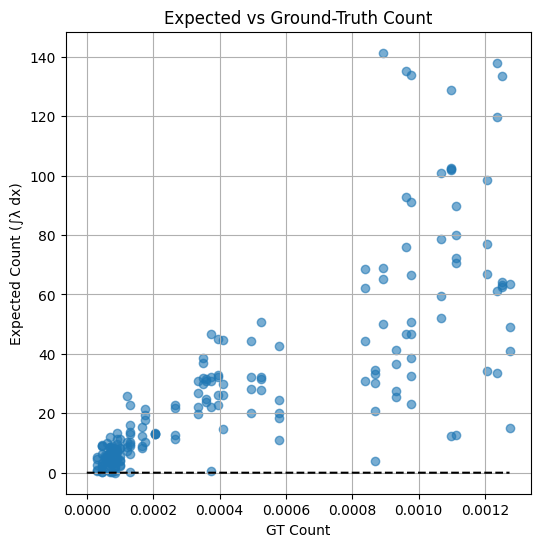

In [20]:
exp_counts = []
gt_counts = []

for prefix in prefixes:
    s = load_sample(prefix)
    lam = s["lambda_pred"]
    lam_gt = s["lambda_gt"]

    H, W = lam.shape
    lam_norm = lam / (H * W)
    lam_gt_norm = lam_gt / (H * W)

    exp_counts.append(lam_norm.sum())
    gt_counts.append(lam_gt_norm.sum())

exp_counts = np.array(exp_counts)
gt_counts = np.array(gt_counts)

plt.figure(figsize=(6, 6))
plt.scatter(gt_counts, exp_counts, alpha=0.6)
plt.plot([0, max(gt_counts)], [0, max(gt_counts)], "k--")

plt.xlabel("GT Count")
plt.ylabel("Expected Count (∫λ dx)")
plt.title("Expected vs Ground-Truth Count")
plt.grid(True)
plt.show()


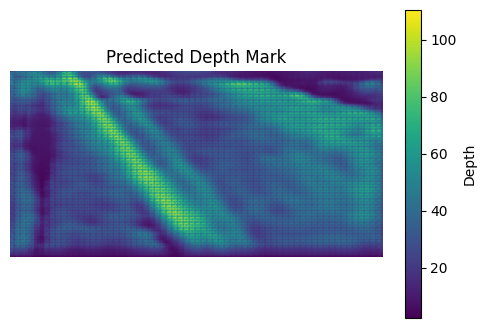

In [21]:
depth = sample["depth_pred"]

if depth is not None:
    plt.figure(figsize=(6, 4))
    plt.imshow(depth, cmap="viridis")
    plt.colorbar(label="Depth")
    plt.title("Predicted Depth Mark")
    plt.axis("off")
    plt.show()
else:
    print("No depth prediction available.")


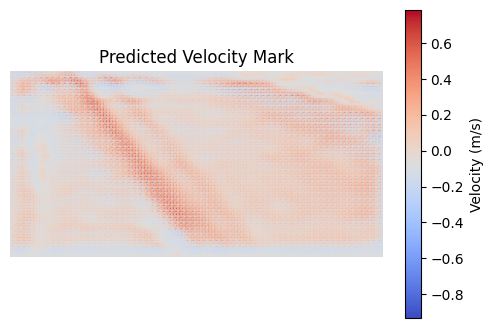

In [22]:
vel = sample["vel_pred"]

if vel is not None:
    plt.figure(figsize=(6, 4))
    plt.imshow(vel, cmap="coolwarm")
    plt.colorbar(label="Velocity (m/s)")
    plt.title("Predicted Velocity Mark")
    plt.axis("off")
    plt.show()
else:
    print("No velocity prediction available.")
